Mykhailo Balaker C00302201

# K-Means Clustering on the Steam Games Dataset

In [1]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
# Load the dataset
dataset = pd.read_csv('steam_games.csv')
print(dataset.shape)

(141900, 43)


## K-Means Clustering Model attempting to cluster games based on popularity and engagement

Given the positive and negative reviews, as well as the playtime, we can attempt to cluster the games into different groups based on their popularity/enjoyment and engagement. First, let's remove any rows with missing values in the relevant columns. Then, we want to convert the playtime from minutes to hours, as the values are currently in minutes and we want to make them more interpretable. Finally, we will plot the data.

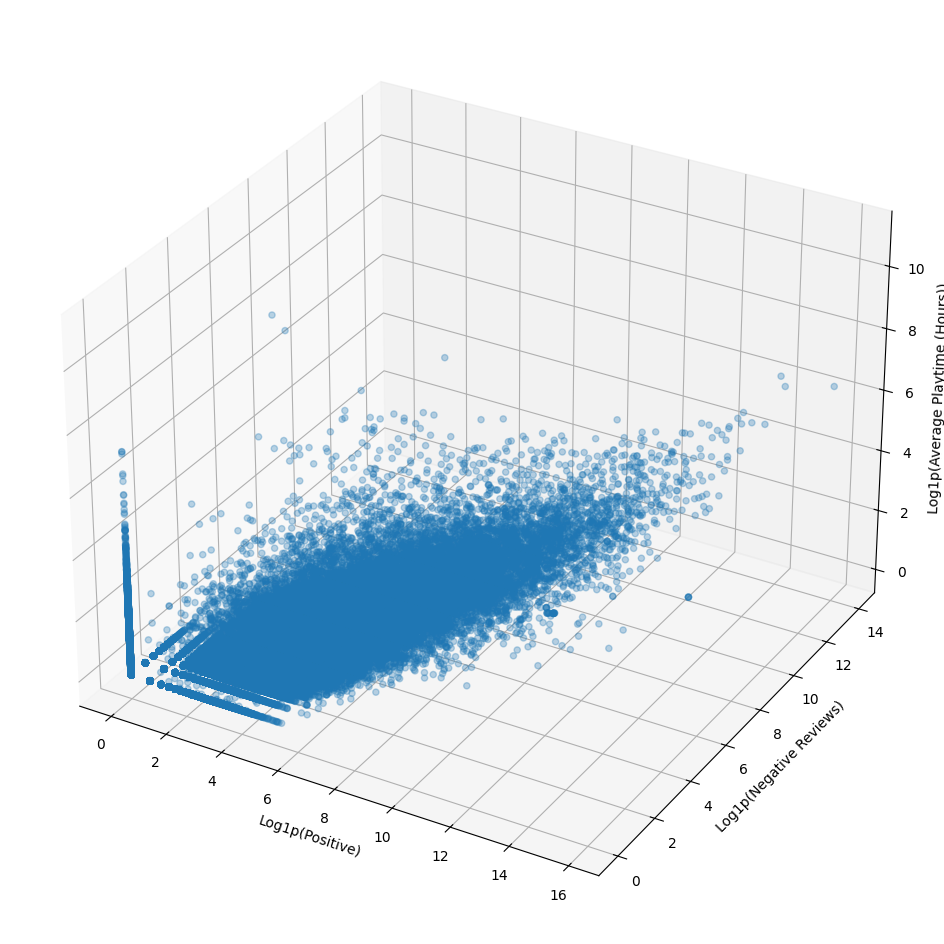

In [2]:
plot_data = dataset.dropna(subset=['positive', 'negative', 'average_playtime_forever'])
plot_data['average_playtime_forever'] = plot_data['average_playtime_forever'] / 60  # Convert to hours
#log(1 + x) transformation
x = np.log1p(plot_data['positive'])
y = np.log1p(plot_data['negative'])
z = np.log1p(plot_data['average_playtime_forever'])

# 3D scatter plot
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')
ax.scatter(x, y, z, alpha=0.3)

ax.set_xlabel('Log1p(Positive)')
ax.set_ylabel('Log1p(Negative Reviews)')
ax.set_zlabel('Log1p(Average Playtime (Hours))')

plt.show()

Without the log(1 + x) transformation, the data is very difficult to interpret due to outliers. The log transformation helps to reduce the impact of extreme values and makes the data more manageable for clustering.

Now that the data is all plotted, we can now cluster the points using k-means clustering.

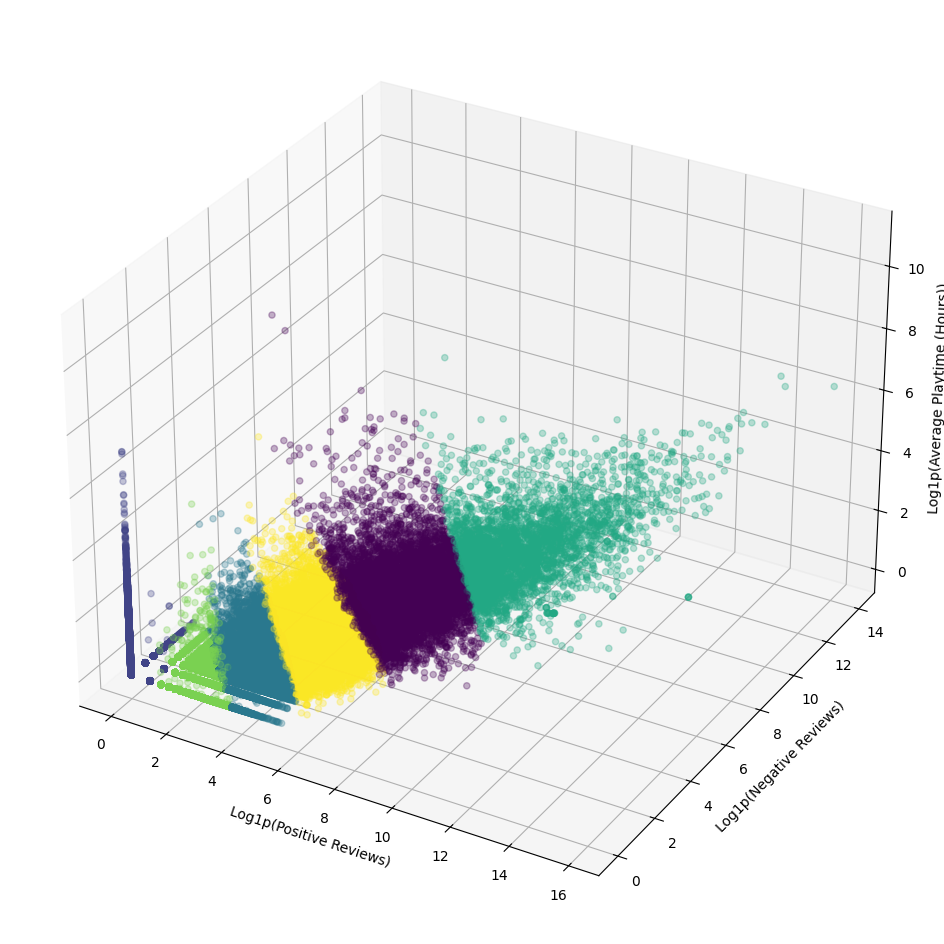

In [3]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=6, random_state=21)
kmeans_data = np.column_stack((x, y, z))
kmeans.fit(kmeans_data)
y_kmeans = kmeans.predict(kmeans_data)

# 3D scatter plot
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')
ax.scatter(x, y, z, c=y_kmeans, cmap='viridis', alpha=0.3)

ax.set_xlabel('Log1p(Positive Reviews)')
ax.set_ylabel('Log1p(Negative Reviews)')
ax.set_zlabel('Log1p(Average Playtime (Hours))')
plt.show()

As can be seen from the plot, the k-means clustering algorithm grouped the games into 6 clusters from low to high review count. The playtime seems to have been largely ignored in the clustering, as the algorithm sees the close relationship between positive and negative reviews as the most important factor in determining the clusters.

Instead of using positive and negative review counts separately, we could instead use the ratio of positive to negative reviews as a single feature for clustering. This would allow us to capture the overall sentiment of the reviews, rather than just the count.

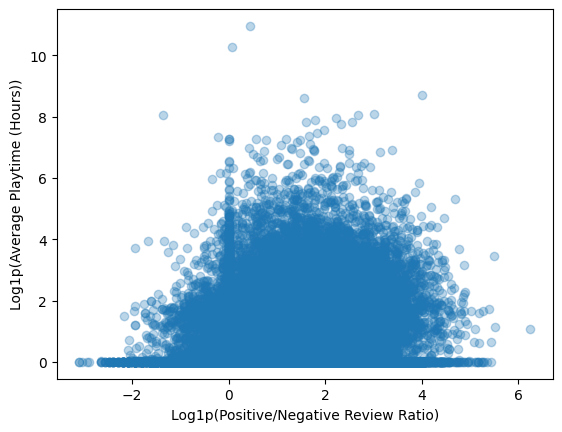

In [4]:
plot_data['review_ratio'] = np.log1p(plot_data['positive']) - np.log1p(plot_data['negative'])

x = plot_data['review_ratio']
#log(1 + x) transformation
y = np.log1p(plot_data['average_playtime_forever'])

plt.scatter(x, y, alpha=0.3)
plt.xlabel('Log1p(Positive/Negative Review Ratio)')
plt.ylabel('Log1p(Average Playtime (Hours))')
plt.show()

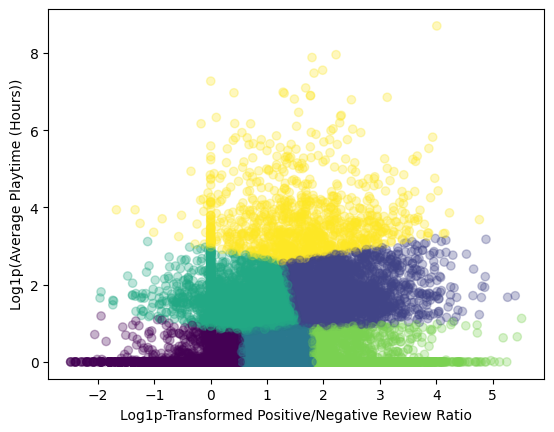

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

kmeans = KMeans(n_clusters=6, random_state=21)
kmeans_data = np.column_stack((x, y))
# Split the data between training and testing data to later verify that it isn't overfitting
data_train, data_test = train_test_split(kmeans_data, test_size=0.7)
# Center and scale the data
data_train_scaled = scaler.fit_transform(data_train)
data_test_scaled = scaler.transform(data_test)

kmeans.fit(data_train_scaled)
y_kmeans = kmeans.predict(data_train_scaled)

plt.scatter(data_train[:, 0], data_train[:, 1], c=y_kmeans, cmap='viridis', alpha=0.3)
plt.xlabel('Log1p-Transformed Positive/Negative Review Ratio')
plt.ylabel('Log1p(Average Playtime (Hours))')
plt.show()

Now, the k-means clustering algorithm produced a much more meaningful result. We can clearly see 6 different groups of games clustered into 6 distinct clusters:

- Games with a review ratio close to 0, but trending more negative, and low average playtime. These are likely games that are not well-received by players and have low engagement. This could be due to a variety of factors, such as the game being a niche title, or the game being released recently and not having had time to accumulate a large number of reviews yet. It also includes games with close to no reviews/players at all.

- Games with a review ratio around 1.0, but trending more positive, and low average playtime. These are likely niche games that are well-received by players but have low engagement, potentially due to being short games or games that are not very replayable.

- Games with a positive review ratio of around 2.0 or more and low average playtime. These are likely more popular games that are well-received by players but have low engagement, most likely because they're short. This is not necessarily a bad thing, as some games are designed to be short experiences, and some players may prefer shorter games.

- Games with a review ratio between -1.0 and 1.0 and medium average playtime. These are your middle-of-the-road games that are neither particularly well-received nor particularly poorly-received, and have a moderate level of engagement. These games may be more niche titles that appeal to a specific audience, or they may be games that are not particularly innovative or exciting. They could also have received a wave of positive/negative reviews at some point that skewed the ratio closer to "Mixed".

- Games with a positive review ratio of around 2.0 or more and medium average playtime. These are likely more popular games that are well-received by players and have a moderate level of engagement.

- Games with a review ratio of mostly >0.0 and high average playtime. These are likely the most popular games that are well-received by players and have a high level of engagement. These games are likely to be the most successful titles on Steam, as they have both a large player base and a high level of engagement.

### Verification

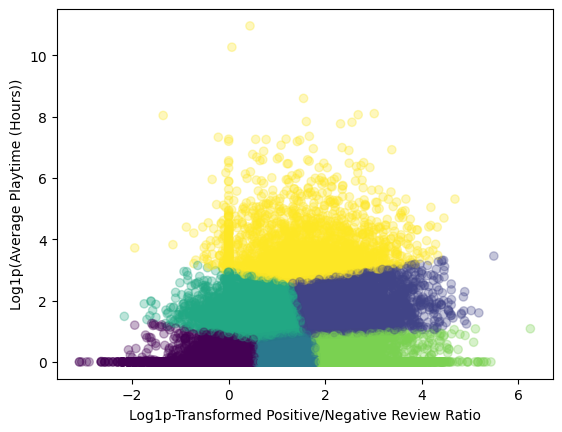

In [7]:
# Predict using the testing data for verification
y_kmeans = kmeans.predict(data_test_scaled)
plt.scatter(data_test[:, 0], data_test[:, 1], c=y_kmeans, cmap='viridis', alpha=0.3)
plt.xlabel('Log1p-Transformed Positive/Negative Review Ratio')
plt.ylabel('Log1p(Average Playtime (Hours))')
plt.show()

As can be seen from the plot, the k-means clustering algorithm produced a very similar result on the test data as it did on the training data. This model is generalizing well to unseen data, and is not overfitting to the training data.

In [8]:
from sklearn.metrics import silhouette_score

score = silhouette_score(data_test_scaled, y_kmeans)

print(f"Silhouette Score={score:.4f}")

Silhouette Score=0.6453


The silhouette score is a measure of how well the clusters are separated from each other. A score of 1 indicates that the clusters are well-isolated, while a score of -1 indicates that the clusters are overlapping. The silhouette score for this model is 0.6453, which indicates that the clusters are well-separated and the model is performing well.

## Conclusion
The k-means clustering analysis revealed that the games on Steam can be effectively clustered into 6 distinct groups based on their review ratio and average playtime. The clusters provide insights into the popularity and engagement of the games. The silhouette score indicates that the clusters are well-separated and the model is performing well, suggesting that the k-means clustering algorithm is a suitable method for analyzing this dataset.